In [154]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score
%matplotlib inline

# Data ingestion

* Data is within the data folder(Locally)

In [155]:
df = pd.read_csv('../data/housing.csv')
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


# EDA processing
* Get the dimensionality and basic dataset info

In [156]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


* Get the statistical details in our data

In [157]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


# Data Imputation
* Using KNNImputer to handle missing data

1. Get the total sum of null values in each column
2. Create a temporary copy
3. retrieve columns with numerica data
4. extract columns that contain at least one missing value
5. update temp dataframe that has empty values

In [158]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [159]:
df_temp= df.copy()
column_list = [ col for col in df_temp.columns if df_temp[col].dtype == 'object']

new_col_list = [col for col in df_temp.loc[:, df_temp.isnull().any()]]

df_temp = df_temp[new_col_list]

* Impute using ML via the KNNImpute from sklearn

In [160]:
knn = KNNImputer(n_neighbors=3)
#fit to train model on relevant data within the df_temp df
knn.fit(df_temp)

,"missing_values missing_values: int, float, str, np.nan or None, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`should be set to np.nan, since `pd.NA` will be converted to np.nan.",nan
,"n_neighbors n_neighbors: int, default=5Number of neighboring samples to use for imputation.",3
,"weights weights: {'uniform', 'distance'} or callable, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- callable : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.",'uniform'
,"metric metric: {'nan_euclidean'} or callable, default='nan_euclidean'Distance metric for searching neighbors. Possible values:- 'nan_euclidean'- callable : a user-defined function which conforms to the definition of ``func_metric(x, y, *, missing_values=np.nan)``. `x` and `y` corresponds to a row (i.e. 1-D arrays) of `X` and `Y`, respectively. The callable should returns a scalar distance value.",'nan_euclidean'
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto theoutput of the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear on themissing indicator even if there are missing values at transform/testtime.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0`... versionadded:: 1.2",False


In [161]:
#Apply the models transformation to the data
array_values = knn.transform(df_temp)

#convert the array into a df with relevant column names(i.e total bedrooms)
df_temp = pd.DataFrame(array_values, columns = new_col_list)

In [162]:
df_temp.isnull().sum()

total_bedrooms    0
dtype: int64

In [163]:
for col in new_col_list:
    df[col] = df_temp[col].values
df.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

In [164]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


# Visualize the data distribution and correlation

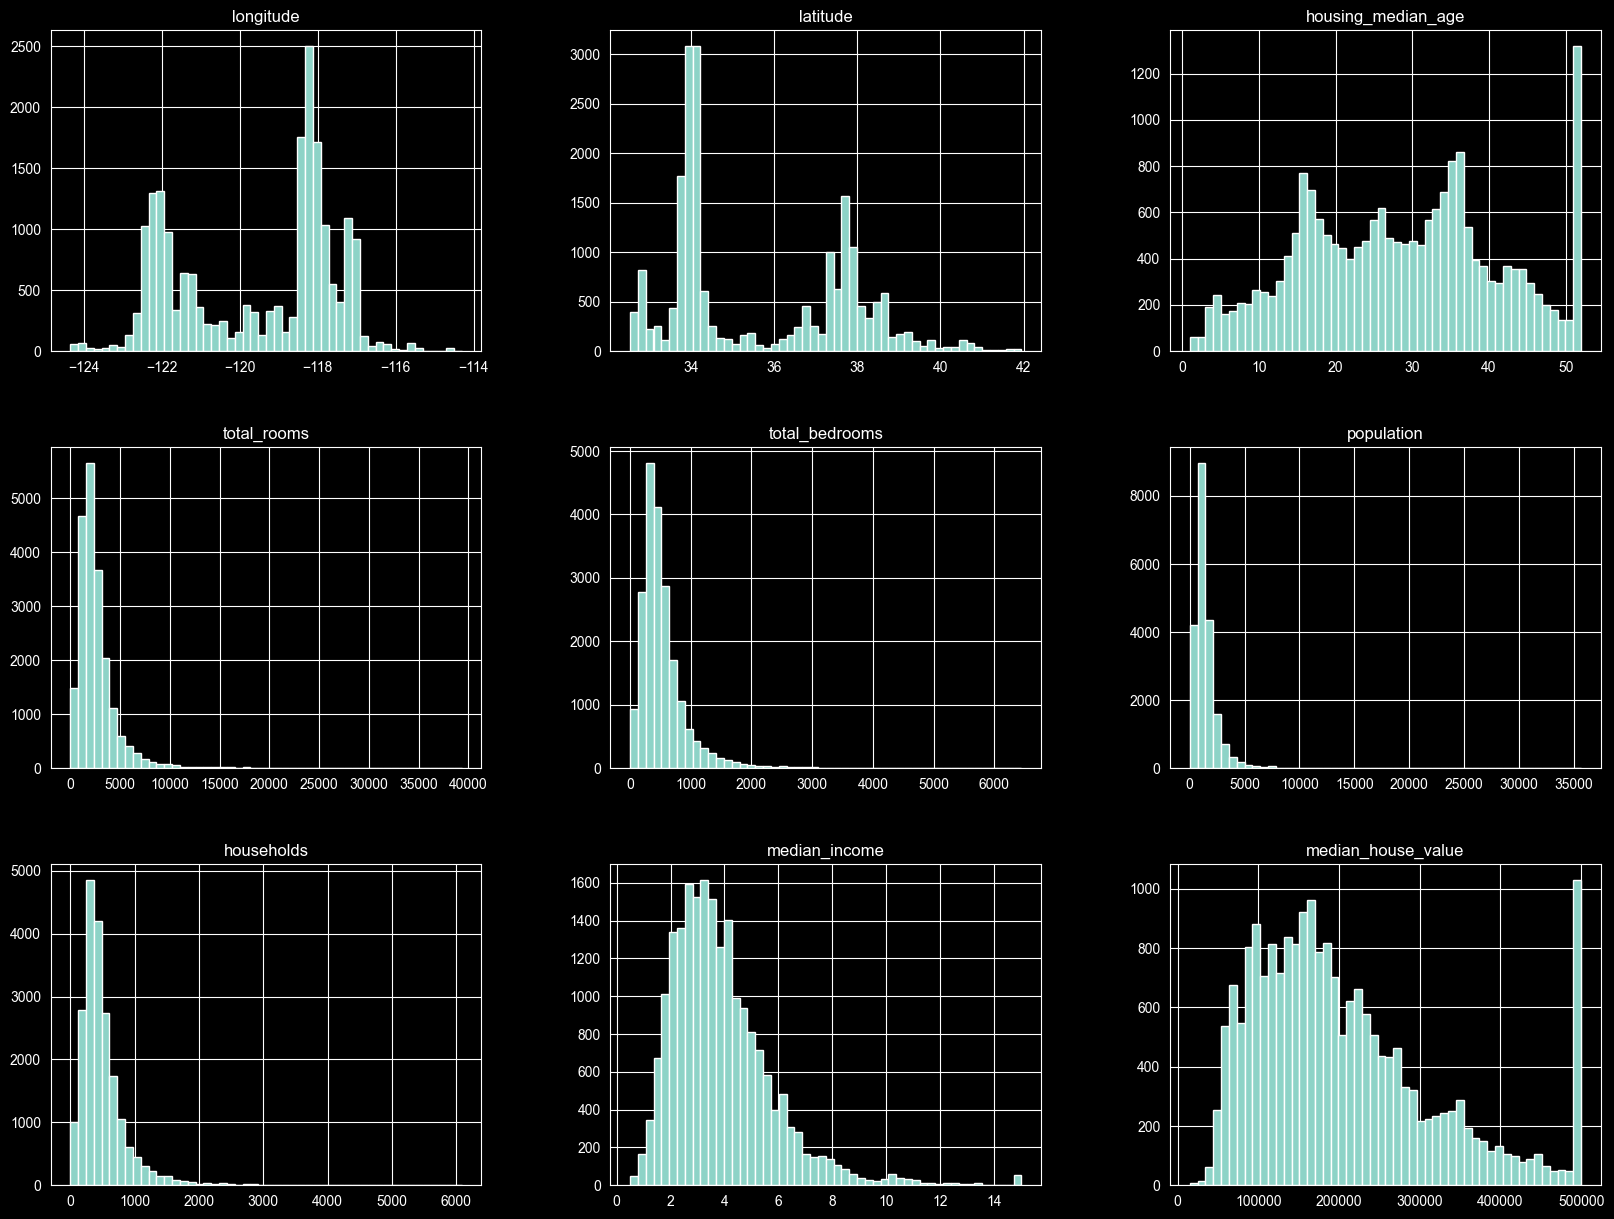

In [165]:
df.hist(bins=50,figsize=(20,15))
plt.show()

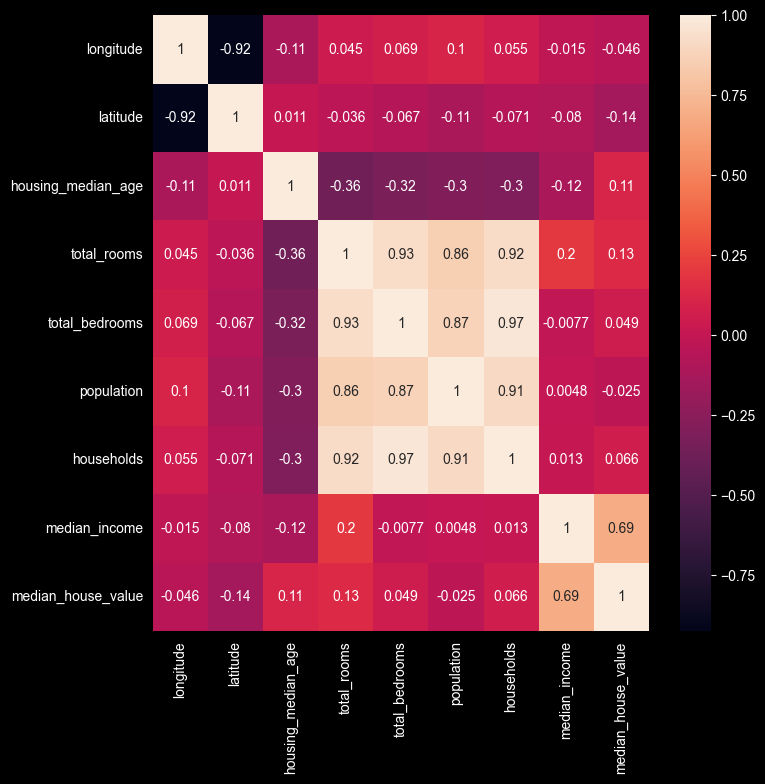

In [166]:
corr = df.select_dtypes(include='number').corr()

plt.figure(figsize=(8,8))
sns.heatmap(corr, annot=True)
plt.show()

# Feature Engineering based on heatmap correlation

In [167]:
TBedmean = np.mean(df['total_bedrooms'])
TBedmax = np.max(df['total_bedrooms'])
TBedmin = np.min(df['total_bedrooms'])
print(f' mean: {TBedmean}, max:{TBedmax}, min:{TBedmin}')

 mean: 537.8705525375617, max:6445.0, min:1.0


* For the below features the Correlations are much closer to 1
* ratio of TotRooms to Households
* ratio of TotBedsrooms to TotRooms
* ration of Population to Households

In [168]:
df['rooms_per_household'] = df['total_rooms'] / df['households']
df['bedrooms_per_room'] = df['total_bedrooms'] / df['total_rooms']
df['population_per_household'] = df['population'] / df['households']


* we can combine the lat and long since they have a -0.92 correlation into 1

In [169]:
df['coordinates'] = df['longitude']/df['latitude']
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   longitude                 20640 non-null  float64
 1   latitude                  20640 non-null  float64
 2   housing_median_age        20640 non-null  float64
 3   total_rooms               20640 non-null  float64
 4   total_bedrooms            20640 non-null  float64
 5   population                20640 non-null  float64
 6   households                20640 non-null  float64
 7   median_income             20640 non-null  float64
 8   median_house_value        20640 non-null  float64
 9   ocean_proximity           20640 non-null  str    
 10  rooms_per_household       20640 non-null  float64
 11  bedrooms_per_room         20640 non-null  float64
 12  population_per_household  20640 non-null  float64
 13  coordinates               20640 non-null  float64
dtypes: float64(13), s

Now that our new features are available, we can now remove the highly correlated features from the original dataframe.

In [170]:
df.drop(['latitude', 'longitude','total_bedrooms','total_rooms','households','population'], axis=1, inplace=True)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   housing_median_age        20640 non-null  float64
 1   median_income             20640 non-null  float64
 2   median_house_value        20640 non-null  float64
 3   ocean_proximity           20640 non-null  str    
 4   rooms_per_household       20640 non-null  float64
 5   bedrooms_per_room         20640 non-null  float64
 6   population_per_household  20640 non-null  float64
 7   coordinates               20640 non-null  float64
dtypes: float64(7), str(1)
memory usage: 1.3 MB


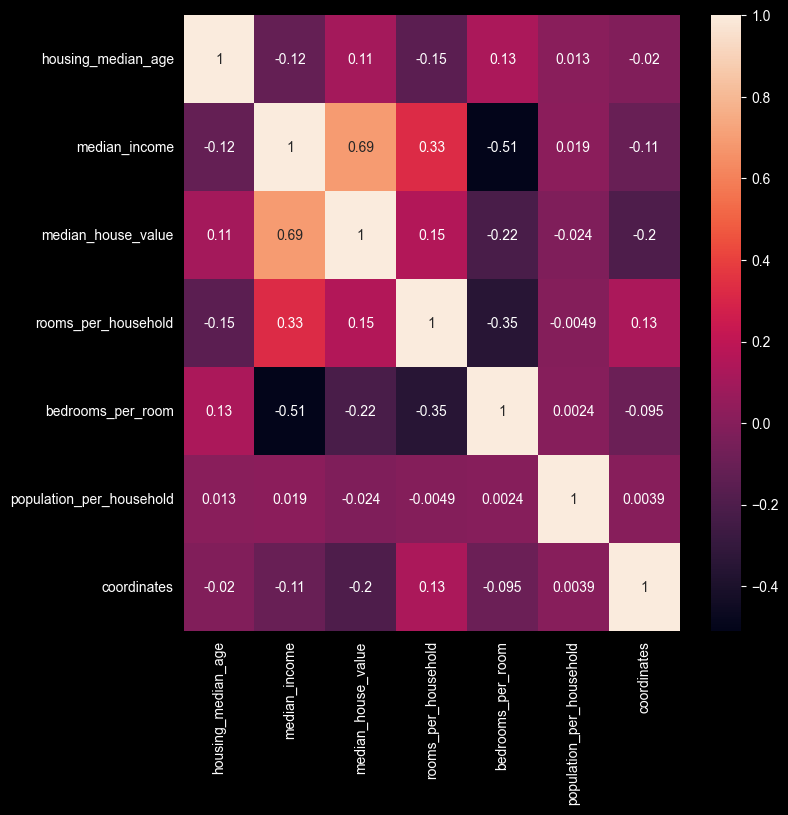

In [171]:
corr = df.select_dtypes(include='number').corr()

plt.figure(figsize=(8, 8))
sns.heatmap(corr, annot=True)
plt.show()

# Using OneShotEncoding on Ocean_Proximity
* First we need to see the unique categories within our Ocean_proximity column
* Count the all unique values grouped by category

### It's best to do this at the beginning after imputation ###

In [172]:
df.ocean_proximity.unique()

<StringArray>
['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND']
Length: 5, dtype: str

In [173]:
df['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


# Then manually define the mapping if we want to
* We can use .map to have more control over an Encoding process
* mapping = {
    '<1H OCEAN': 0,
    'INLAND': 1,
    'NEAR OCEAN': 2,
    'NEAR BAY': 3,
    'ISLAND': 4
}
* df['ocean_proximity'] = df['ocean_proximity'].map(mapping)
* NB: We won't use the .map route because the get_dummies is perfect for a linear regression model

In [174]:
df_encoded = pd.get_dummies(data= df , columns= ['ocean_proximity'], dtype=int)
df_encoded.head()

,housing_median_age,median_income,median_house_value,rooms_per_household,bedrooms_per_room,population_per_household,coordinates,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,41.0,8.3252,452600.0,6.984127,0.146591,2.555556,-3.226769,0,0,0,1,0
1,21.0,8.3014,358500.0,6.238137,0.155797,2.109842,-3.228209,0,0,0,1,0
2,52.0,7.2574,352100.0,8.288136,0.129516,2.802260,-3.229590,0,0,0,1,0
3,52.0,5.6431,341300.0,5.817352,0.184458,2.547945,-3.229855,0,0,0,1,0
4,52.0,3.8462,342200.0,6.281853,0.172096,2.181467,-3.229855,0,0,0,1,0


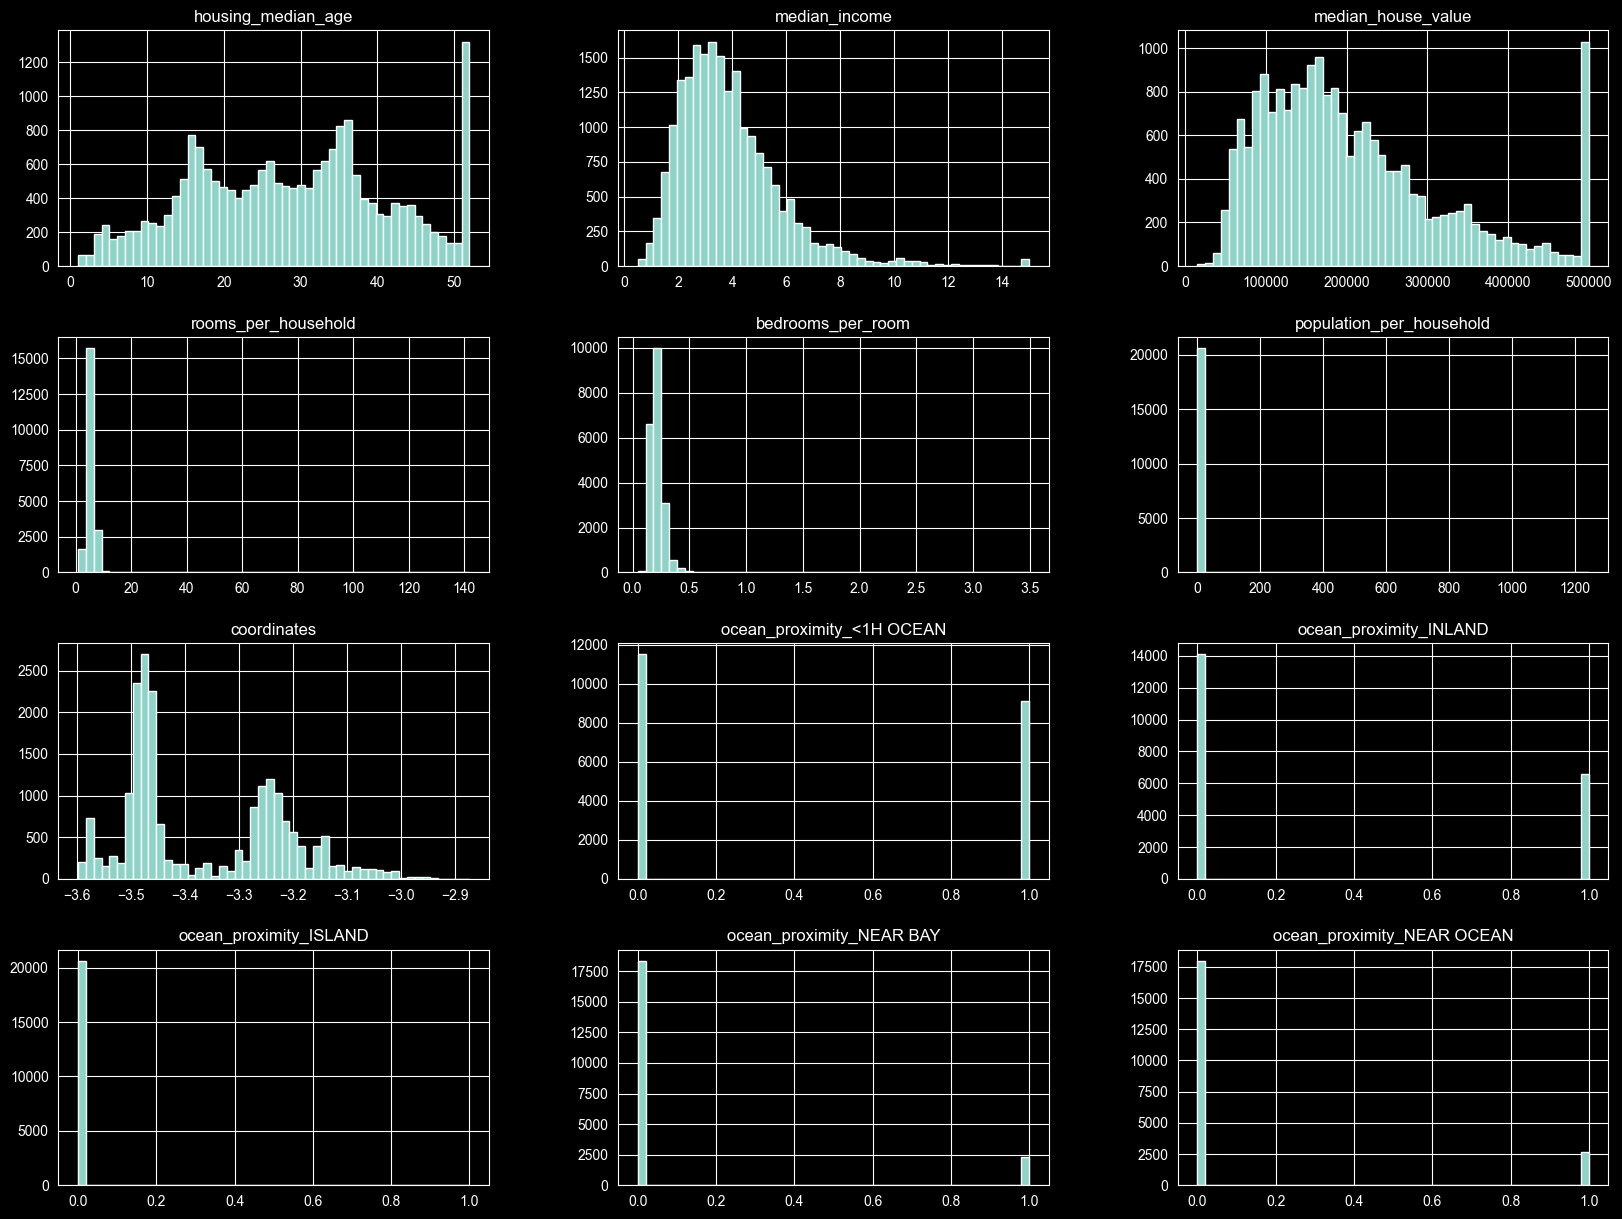

In [175]:
df_encoded.hist(bins=50,figsize=(20,15))
plt.show()

# Model training and testing before outlier handling

In [176]:
X = df_encoded.drop('median_house_value', axis=1)
y = df_encoded['median_house_value']

In [177]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [178]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [179]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [180]:
y_pred = model.predict(X_test)

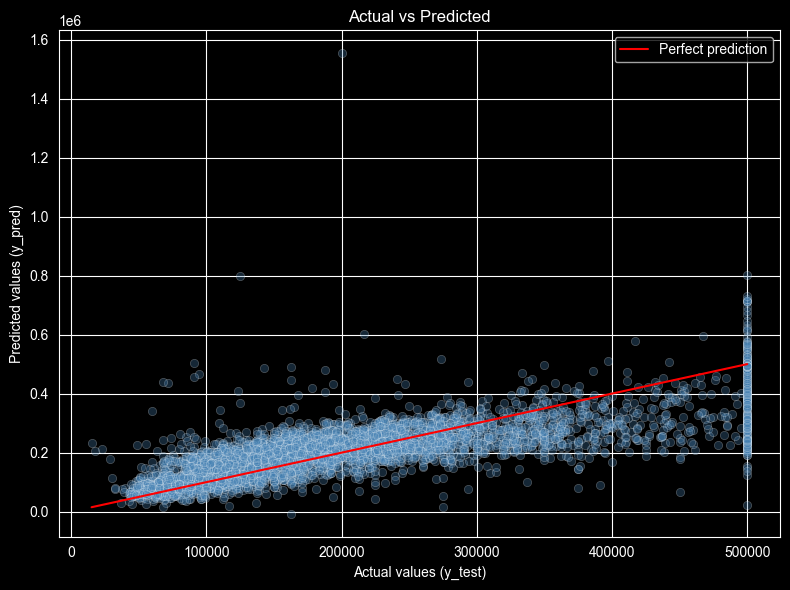

In [181]:
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.3, color='steelblue')

# Perfect prediction line
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red', label='Perfect prediction')

plt.xlabel('Actual values (y_test)')
plt.ylabel('Predicted values (y_pred)')
plt.title('Actual vs Predicted')
plt.legend()
plt.tight_layout()
plt.show()

In [182]:
print("MAE: ", mean_absolute_error(y_test, y_pred))
print("MSE: ", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²:  ", r2_score(y_test, y_pred))

MAE:  54486.07618760324
MSE:  6353151808.612915
RMSE: 79706.66100529437
R²:   0.5151779395512521


### Metric:
* MAE - Average prediction error in the same units as house prices
* MSE - Same but penalises large errors more heavily
* RMSE - MSE but back in original units — most interpretable
* R² - How much variance our model explains (1.0 = perfect, 0 = useless)

### Observation:

# To improve model performance we will remove outliers

* we will deal with outlier for 'median_house_age' and 'median_house_value'
* I used 2 approaches the "cap removal" and "IQR manipulation"

 We can see from our EDA process and distribution visuals above that:
1. housing_median_age has a cap/max limit of 50 years
2. median_hose_value has a cap/max limit of 500000

In [183]:
df_encoded = df_encoded[df_encoded['median_house_value'] < 500000]
df_encoded = df_encoded[df_encoded['housing_median_age'] < 50]
df_encoded.info()
df_encoded.head()

<class 'pandas.DataFrame'>
Index: 18388 entries, 0 to 20639
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   housing_median_age          18388 non-null  float64
 1   median_income               18388 non-null  float64
 2   median_house_value          18388 non-null  float64
 3   rooms_per_household         18388 non-null  float64
 4   bedrooms_per_room           18388 non-null  float64
 5   population_per_household    18388 non-null  float64
 6   coordinates                 18388 non-null  float64
 7   ocean_proximity_<1H OCEAN   18388 non-null  int64  
 8   ocean_proximity_INLAND      18388 non-null  int64  
 9   ocean_proximity_ISLAND      18388 non-null  int64  
 10  ocean_proximity_NEAR BAY    18388 non-null  int64  
 11  ocean_proximity_NEAR OCEAN  18388 non-null  int64  
dtypes: float64(7), int64(5)
memory usage: 1.8 MB


,housing_median_age,median_income,median_house_value,rooms_per_household,bedrooms_per_room,population_per_household,coordinates,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,41.0,8.3252,452600.0,6.984127,0.146591,2.555556,-3.226769,0,0,0,1,0
1,21.0,8.3014,358500.0,6.238137,0.155797,2.109842,-3.228209,0,0,0,1,0
8,42.0,2.0804,226700.0,4.294118,0.260274,2.026891,-3.230973,0,0,0,1,0
20,40.0,1.3578,147500.0,4.524096,0.245007,2.463855,-3.230383,0,0,0,1,0
21,42.0,1.7135,159800.0,4.478142,0.223917,2.538251,-3.230383,0,0,0,1,0


* Using IQR in combination with the cut-off caps
* Reason for this is to handle the outliers and without heavily reducing the dataset

In [184]:
Q1 = df_encoded['median_house_value'].quantile(0.25)
Q3 = df_encoded['median_house_value'].quantile(0.75)
IQR = Q3 - Q1

df_encoded = df_encoded[(df_encoded['median_house_value'] >= Q1 - 1.5 * IQR) &
                         (df_encoded['median_house_value'] <= Q3 + 1.5 * IQR)]

Q1 = df_encoded['housing_median_age'].quantile(0.25)
Q3 = df_encoded['housing_median_age'].quantile(0.75)
IQR = Q3 - Q1

df_encoded = df_encoded[(df_encoded['housing_median_age'] >= Q1 - 1.5 * IQR) &
                         (df_encoded['housing_median_age'] <= Q3 + 1.5 * IQR)]

# Model Training without Outliers to improved performance
* The aim here is to improve the results model accuracy without the caps and limits set

In [185]:
#We define X and y
X = df_encoded.drop('median_house_value', axis=1)
y = df_encoded['median_house_value']

In [186]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [187]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [188]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [189]:
y_pred = model.predict(X_test)

2. Show the actual distribution and the predicted value line

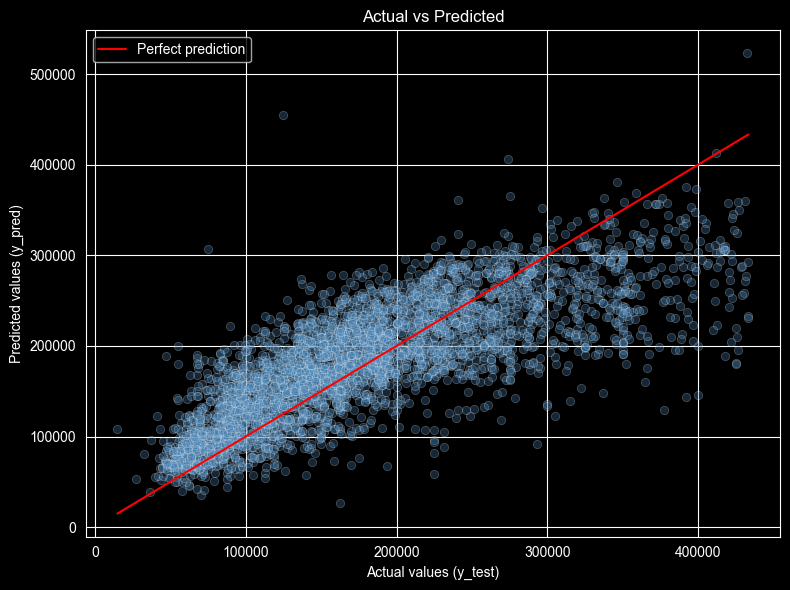

In [190]:
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.3, color='steelblue')

# Perfect prediction line
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red', label='Perfect prediction')

plt.xlabel('Actual values (y_test)')
plt.ylabel('Predicted values (y_pred)')
plt.title('Actual vs Predicted')
plt.legend()
plt.tight_layout()
plt.show()

2. Model Metrics

In [191]:
print("MAE: ", mean_absolute_error(y_test, y_pred))
print("MSE: ", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²:  ", r2_score(y_test, y_pred))

MAE:  41325.86381349227
MSE:  2988298331.650909
RMSE: 54665.33025282944
R²:   0.6024594971120285


# Model training using a Polynomial regression
* Using a linear regression for a dataset that shows a non-linear relationship yeilds unfavourable results

In [192]:
poly_model = Pipeline([
    ('poly', PolynomialFeatures(degree=2)),
    ('linear', LinearRegression())
])

poly_model.fit(X_train, y_train)
y_pred = poly_model.predict(X_test)

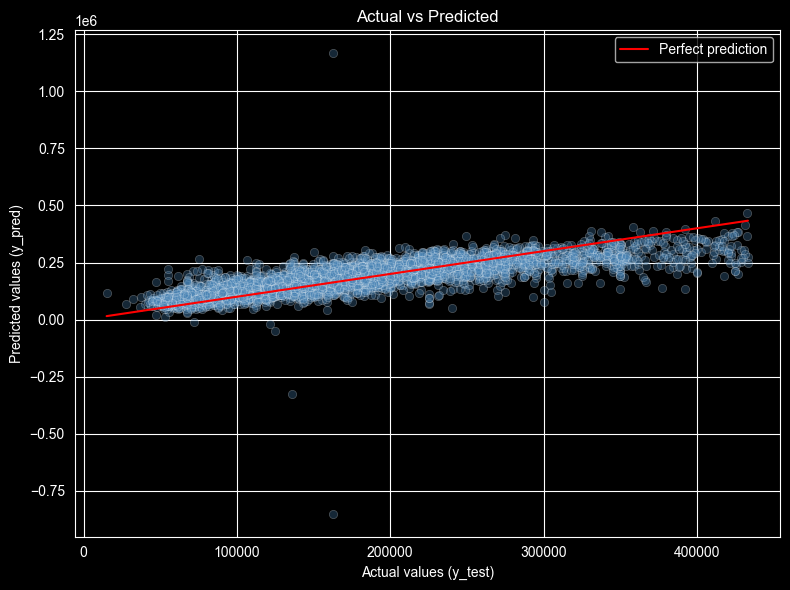

In [193]:
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.3, color='steelblue')

# Perfect prediction line
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red', label='Perfect prediction')

plt.xlabel('Actual values (y_test)')
plt.ylabel('Predicted values (y_pred)')
plt.title('Actual vs Predicted')
plt.legend()
plt.tight_layout()
plt.show()

In [194]:
print("MAE: ", mean_absolute_error(y_test, y_pred))
print("MSE: ", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²:  ", r2_score(y_test, y_pred))

MAE:  38220.01659152647
MSE:  3121856881.6725698
RMSE: 55873.57945999674
R²:   0.5846918824872642


# Model training with Random forest Regressor

Used RandomForest Regressor because it handles non-linear relationships, doesn't require feature scaling, handles the remaining outliers better.

In [195]:
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

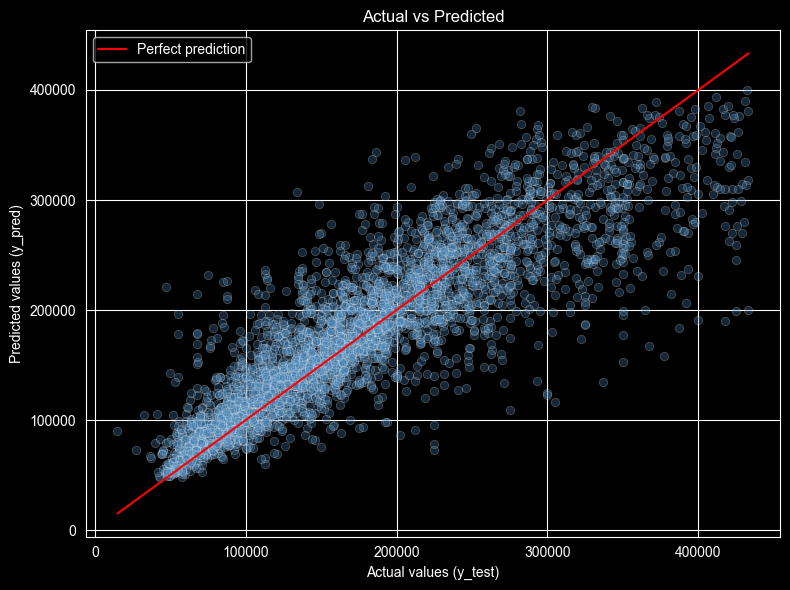

In [196]:
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.3, color='steelblue')

# Perfect prediction line
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red', label='Perfect prediction')

plt.xlabel('Actual values (y_test)')
plt.ylabel('Predicted values (y_pred)')
plt.title('Actual vs Predicted')
plt.legend()
plt.tight_layout()
plt.show()

In [197]:
print("MAE: ", mean_absolute_error(y_test, y_pred))
print("MSE: ", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²:  ", r2_score(y_test, y_pred))

MAE:  30409.281495145628
MSE:  1888341367.490135
RMSE: 43455.0499653393
R²:   0.7487894133911783
